<a href="https://colab.research.google.com/github/kvikaee/data-analysis-python/blob/main/5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Кошурина Виктория Евгеньевна

412977

# Задание 5. Разведочный анализ данных (Exploratory Data Analysis, EDA) с использованием seaborn

Цель — научиться эффективно исследовать структуру данных, выявлять паттерны, корреляции и кластеризацию между объектами и признаками, а также строить сложные визуализации, такие как clustermap.


In [ ]:
import numpy as np
import pandas as pd
import scipy.stats as sps

import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from tabulate import tabulate

%matplotlib inline

[Ссылка на датасет](https://disk.yandex.ru/d/9xHKBELeT1pBSA)

In [ ]:
imdb = 'spotify_dataset.csv'
df = pd.read_csv(imdb)

In [ ]:
print(tabulate(
    df.tail(5),
    headers='keys',
    tablefmt='simple_grid',
    showindex=False,
    maxcolwidths=20
))

┌─────────┬─────────────────────────────┬───────────────────────────┬────────────────────────────┬──────────────────────┬───────────┬────────────────────┬────────────────────┬──────────────────────┬──────────────────────┬────────────────┬─────────────────┬──────────────┬────────────────┬──────────┬────────────┬───────────────┬────────────────┬────────────┬─────────┬─────────────────┬───────────┬─────────┐
│   Index │   Highest Charting Position │   Number of Times Charted │ Week of Highest Charting   │ Song Name            │ Streams   │ Artist             │   Artist Followers │ Song ID              │ Genre                │ Release Date   │ Weeks Charted   │   Popularity │   Danceability │   Energy │   Loudness │   Speechiness │   Acousticness │   Liveness │   Tempo │   Duration (ms) │   Valence │ Chord   │
├─────────┼─────────────────────────────┼───────────────────────────┼────────────────────────────┼──────────────────────┼───────────┼────────────────────┼────────────────────┼───────

1.	Общая характеристика данных
*	Количество строк и столбцов.
*	Типы признаков (числовые, категориальные).
*	Описание ключевых признаков, особенно категориального с ≥20 значениями.


In [ ]:
num_rows = len(df)  # количество строк
num_columns = len(df.columns)  # количество признаков

# Описание признаков в датасете
columns_description = {
    "Тип данных": df.dtypes,
    "Шкала": [
        "Категориальная" if df[col].dtype == 'object' else
        "Числовая" if df[col].dtype in ['int64', 'float64'] else "Неопределено"
        for col in df.columns
    ]
}

description_df = pd.DataFrame(columns_description)

# Выводим информацию о количестве строк и признаков
print(f"Количество строк: {num_rows}")
print(f"Количество признаков: {num_columns}")

# Строим таблицу с описанием признаков
description_df

Количество строк: 1556
Количество признаков: 23


,Тип данных,Шкала
Index,int64,Числовая
Highest Charting Position,int64,Числовая
Number of Times Charted,int64,Числовая
Week of Highest Charting,object,Категориальная
Song Name,object,Категориальная
Streams,object,Категориальная
Artist,object,Категориальная
Artist Followers,object,Категориальная
Song ID,object,Категориальная
Genre,object,Категориальная


2.	Анализ пропусков
*	Выявление пропущенных значений (включая скрытые, например: "?", "N/A", пустые строки).
*	Визуализация пропусков с помощью seaborn.heatmap().


In [ ]:
na_counts = df.isna().sum()

# Скрытые маркеры пропусков
hidden_na_values = ["?", "N/A", "NA", "n/a", "NaN", " ", "", "[]"]
mask_hidden = df.isin(hidden_na_values)

hidden_na_counts = mask_hidden.sum()

print("Явные пропуски:\n", na_counts)
print("\nСкрытые пропуски:\n", hidden_na_counts)

Явные пропуски:
 Index                        0
Highest Charting Position    0
Number of Times Charted      0
Week of Highest Charting     0
Song Name                    0
Streams                      0
Artist                       0
Artist Followers             0
Song ID                      0
Genre                        0
Release Date                 0
Weeks Charted                0
Popularity                   0
Danceability                 0
Energy                       0
Loudness                     0
Speechiness                  0
Acousticness                 0
Liveness                     0
Tempo                        0
Duration (ms)                0
Valence                      0
Chord                        0
dtype: int64

Скрытые пропуски:
 Index                         0
Highest Charting Position     0
Number of Times Charted       0
Week of Highest Charting      0
Song Name                     0
Streams                       0
Artist                        0
Artist Follow

/tmp/ipython-input-2956055960.py:15: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


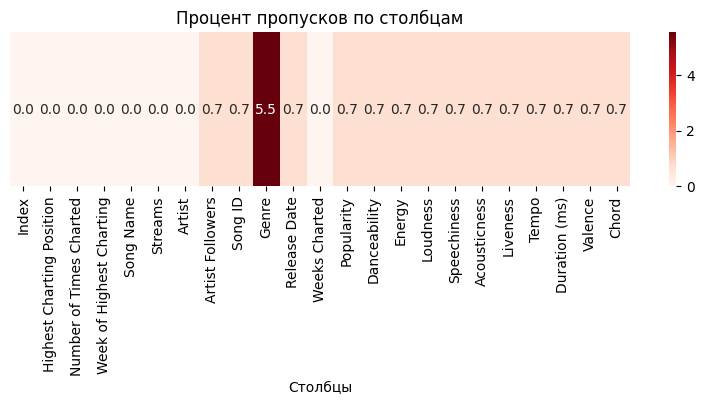

In [ ]:
mask_all_na = df.isna() | df.isin(hidden_na_values)

missing_pct = mask_all_na.mean() * 100   # % пропусков в каждом столбце

plt.figure(figsize=(10, 2))
sns.heatmap(
    missing_pct.to_frame().T,  # превращаем в 1 строку
    annot=True,
    fmt=".1f",
    cmap="Reds"
)
plt.title("Процент пропусков по столбцам")
plt.yticks([])   # строка одна, её подпись не нужна
plt.xlabel("Столбцы")
plt.tight_layout()
plt.show()


In [ ]:
# rows_with_hidden_missing = df[mask_hidden.any(axis=1)]

# Выводим их
# print(tabulate(rows_with_hidden_missing, headers='keys', tablefmt='fancy_grid', showindex=False))

Я приняла решение удалить строчки, где данные пропущены, так как они не повлияют сильно на процесс.

(Там было 11 строчек почти с полностью отсутствующими данными их и удаляем, а где жанр только пропущен, мы обработаем немного позже.)

In [ ]:
df_clean = df.copy()

# Считаем количество пропусков в каждой строке
missing_count = mask_hidden.sum(axis=1)

# Удаляем строки где пропущено более 1 признака
df_clean = df_clean[missing_count <= 1]

# Проверяем размер
print(f"Исходный датасет: {df.shape[0]} строк")
print(f"Очищенный датасет: {df_clean.shape[0]} строк")
print(f"Удалено строк (где пропущено >1 признака): {df.shape[0] - df_clean.shape[0]}")

# Проверяем сколько осталось пропусков только в Genre
remaining_empty_genres = (df_clean['Genre'].astype(str) == '[]').sum()
print(f"\nОсталось пропусков только в Genre: {remaining_empty_genres}")


Исходный датасет: 1556 строк
Очищенный датасет: 1545 строк
Удалено строк (где пропущено >1 признака): 11

Осталось пропусков только в Genre: 75


Чтобы заполнить жанры, мы заполним их модой по артисту.
Если жанр пропущен у артиста, кто попадается в датасате всего 1 раз, заполняем их популярными жанрами.

In [ ]:
import ast
from collections import Counter

In [ ]:
def parse_genre(genre_str):
    """Парсит строку с жанром в список"""
    if pd.isna(genre_str):
        return []
    if str(genre_str).strip() == '[]':
        return []
    try:
        return ast.literal_eval(genre_str)
    except:
        return []

def is_empty_genre(genre_str):
    """Проверяет пуст ли жанр"""
    return parse_genre(genre_str) == []

# Получаем топ жанры по популярности
def get_top_genres_by_popularity(df, top_n=3):
    """Находит топ жанры по популярности"""
    all_genres = []
    for genre_str in df['Genre']:
        genres = parse_genre(genre_str)
        all_genres.extend(genres)

    if not all_genres:
        return ['Unknown', 'Unknown', 'Unknown']

    genre_counts = Counter(all_genres)
    top_genres = [genre for genre, _ in genre_counts.most_common(top_n)]

    # Если меньше 3 жанров, дополняем
    while len(top_genres) < 3:
        top_genres.append('Unknown')

    return top_genres[:3]

# Получаем топ жанры для подстраховки
global_top_genres = get_top_genres_by_popularity(df_clean, top_n=3)
print(f"Топ жанры по популярности: {global_top_genres}")

# Функция для получения жанров артиста
def get_artist_genres(artist, df, top_n=3):
    """Находит топ жанры у артиста"""
    artist_data = df[df['Artist'] == artist]

    # Расплющиваем список жанров
    all_genres = []
    for genre_str in artist_data['Genre']:
        genres = parse_genre(genre_str)
        all_genres.extend(genres)

    if not all_genres:
        return None  # Нет жанров у этого артиста

    # Находим топ жанры
    genre_counts = Counter(all_genres)
    top_genres = [genre for genre, _ in genre_counts.most_common(top_n)]

    # Если меньше 3 жанров, дополняем глобальными топ-жанрами
    while len(top_genres) < 3:
        for g in global_top_genres:
            if g not in top_genres:
                top_genres.append(g)
                break
        if len(top_genres) < 3:
            top_genres.append('Unknown')

    return top_genres[:3]

# Заполняем пропущенные жанры
for idx, row in df_clean.iterrows():
    genre_list = parse_genre(row['Genre'])
    if genre_list == []:  # Если жанр пуст
        artist_genres = get_artist_genres(row['Artist'], df_clean, top_n=3)
        if artist_genres:
            df_clean.at[idx, 'Genre'] = str(artist_genres)
        else:
            # Если у артиста нет жанров, используем глобальные топ жанры
            df_clean.at[idx, 'Genre'] = str(global_top_genres)

# Проверяем сколько осталось пусто
empty_after = df_clean['Genre'].apply(is_empty_genre).sum()
print(f"\nПропусков в жанрах после заполнения: {empty_after}")

# Проверим несколько примеров
print("\nПримеры заполненных жанров:")
print(tabulate(df_clean[['Artist', 'Genre']].head(5), headers='keys', tablefmt='fancy_grid', showindex=False))


Топ жанры по популярности: ['pop', 'rap', 'dance pop']

Пропусков в жанрах после заполнения: 0

Примеры заполненных жанров:
╒════════════════╤════════════════════════════════════════╕
│ Artist         │ Genre                                  │
╞════════════════╪════════════════════════════════════════╡
│ Måneskin       │ ['indie rock italiano', 'italian pop'] │
├────────────────┼────────────────────────────────────────┤
│ The Kid LAROI  │ ['australian hip hop']                 │
├────────────────┼────────────────────────────────────────┤
│ Olivia Rodrigo │ ['pop']                                │
├────────────────┼────────────────────────────────────────┤
│ Ed Sheeran     │ ['pop', 'uk pop']                      │
├────────────────┼────────────────────────────────────────┤
│ Lil Nas X      │ ['lgbtq+ hip hop', 'pop rap']          │
╘════════════════╧════════════════════════════════════════╛


3.	Статистические оценки
*	Для числовых признаков: среднее, медиана, стандартное отклонение, мин/макс.
*	Для категориальных признаков: частоты категорий (мода, распределение).
*	Представление в виде таблиц и графиков (countplot, histplot, boxplot и др.).


In [ ]:
cols_to_convert = ['Popularity', 'Danceability', 'Energy', 'Loudness', 'Speechiness',
                   'Acousticness', 'Liveness', 'Tempo', 'Duration (ms)', 'Valence']

# Конвертируем в числовые
for col in cols_to_convert:
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

# Проверяем типы
print(df_clean[cols_to_convert].dtypes)

Popularity         int64
Danceability     float64
Energy           float64
Loudness         float64
Speechiness      float64
Acousticness     float64
Liveness         float64
Tempo            float64
Duration (ms)      int64
Valence          float64
dtype: object


In [ ]:
# 1. ЧИСЛОВЫЕ ПРИЗНАКИ

# Определяем числовые колонки
numeric_cols = df_clean.select_dtypes(include=['number']).columns.tolist()

# Описательная статистика
numeric_stats = df_clean[numeric_cols].describe().T
numeric_stats['median'] = df_clean[numeric_cols].median()
numeric_stats = numeric_stats[['count', 'mean', 'median', 'std', 'min', 'max']]

print("Статистика числовых признаков:")
print(tabulate(numeric_stats, headers='keys', tablefmt='fancy_grid', showindex=True))


Статистика числовых признаков:
╒═══════════════════════════╤═════════╤═══════════════╤═════════════╤══════════════╤══════════════╤════════════╕
│                           │   count │          mean │      median │          std │          min │        max │
╞═══════════════════════════╪═════════╪═══════════════╪═════════════╪══════════════╪══════════════╪════════════╡
│ Index                     │    1545 │    779.136    │    780      │   449.594    │     1        │   1556     │
├───────────────────────────┼─────────┼───────────────┼─────────────┼──────────────┼──────────────┼────────────┤
│ Highest Charting Position │    1545 │     87.8252   │     80      │    58.132    │     1        │    200     │
├───────────────────────────┼─────────┼───────────────┼─────────────┼──────────────┼──────────────┼────────────┤
│ Number of Times Charted   │    1545 │     10.6841   │      4      │    16.3898   │     1        │    142     │
├───────────────────────────┼─────────┼───────────────┼──────────

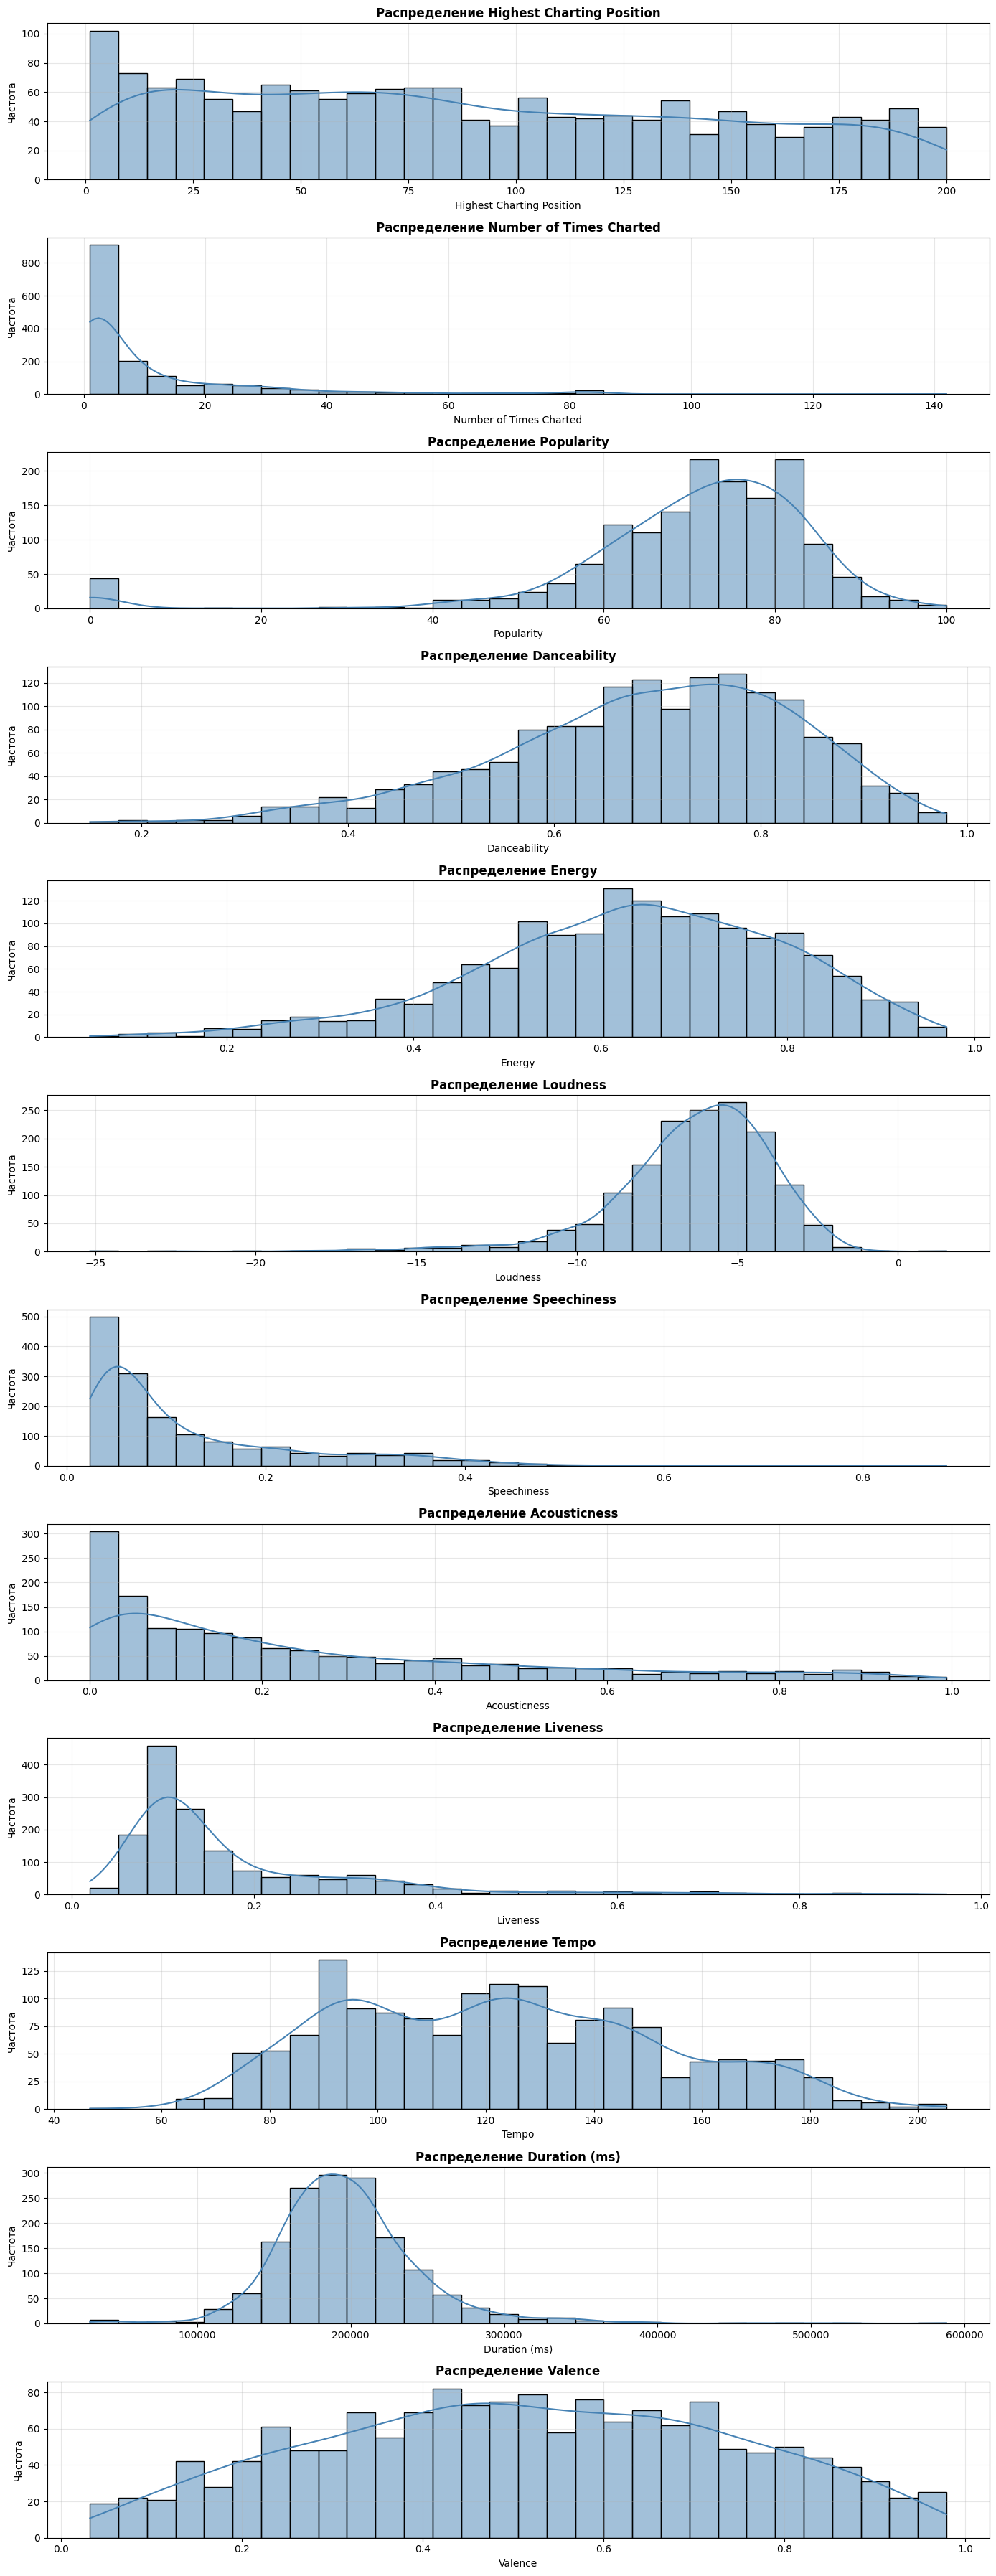

In [ ]:
numeric_cols_filtered = [col for col in numeric_cols if col != 'Index']

# Визуализация: гистограммы с KDE
fig, axes = plt.subplots(len(numeric_cols_filtered), 1, figsize=(14, 3*len(numeric_cols_filtered)))

for idx, col in enumerate(numeric_cols_filtered):
    # Гистограмма с KDE
    sns.histplot(data=df_clean, x=col, kde=True, ax=axes[idx], bins=30, color='steelblue')
    axes[idx].set_title(f'Распределение {col}', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel('Частота')
    axes[idx].grid(alpha=0.3)

plt.tight_layout()
plt.show()

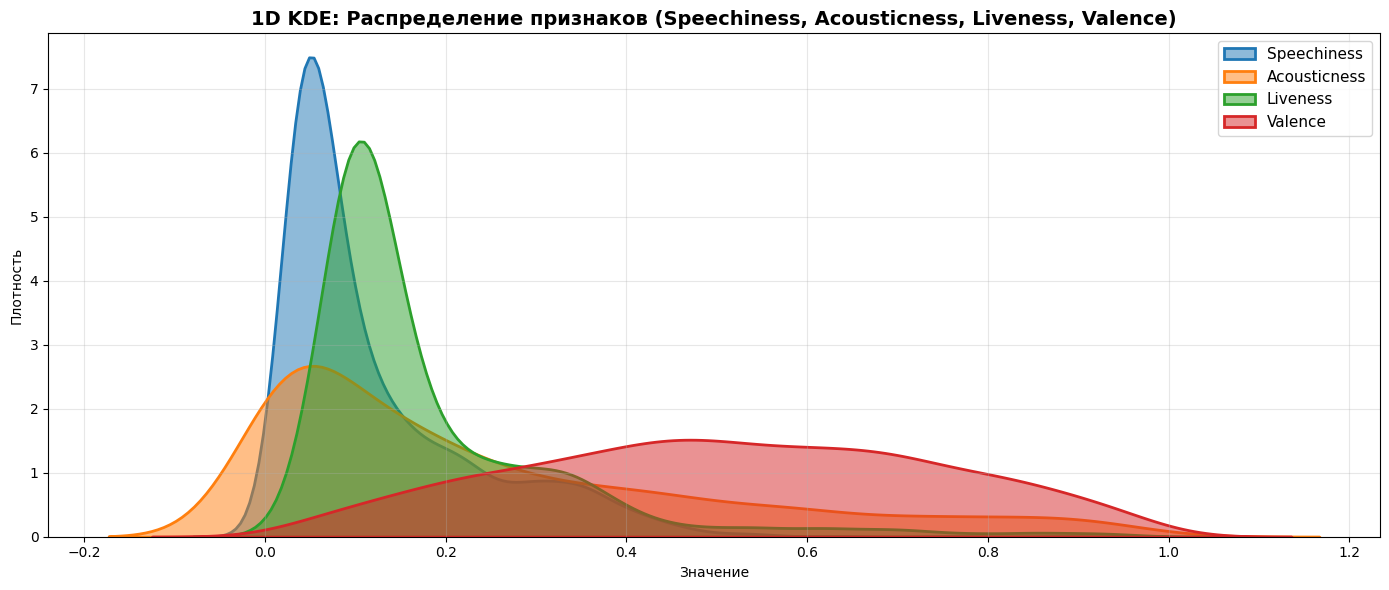

In [ ]:
selected_features = ['Speechiness', 'Acousticness', 'Liveness', 'Valence']

plt.figure(figsize=(14, 6))

for feature in selected_features:
    sns.kdeplot(data=df_clean, x=feature, fill=True, alpha=0.5, linewidth=2, label=feature)

plt.title('1D KDE: Распределение признаков (Speechiness, Acousticness, Liveness, Valence)',
          fontsize=14, fontweight='bold')
plt.xlabel('Значение')
plt.ylabel('Плотность')
plt.legend(loc='upper right', fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
all_individual_genres = []
for genre_str in df_clean['Genre']:
    genres = parse_genre(genre_str)
    all_individual_genres.extend(genres)
genre_counts = Counter(all_individual_genres)

In [ ]:
cat_cols = df_clean.select_dtypes(include=['object']).columns
print(cat_cols)


Index(['Week of Highest Charting', 'Song Name', 'Streams', 'Artist',
       'Artist Followers', 'Song ID', 'Genre', 'Release Date', 'Weeks Charted',
       'Chord'],
      dtype='object')


In [ ]:
# КАТЕГОРИАЛЬНЫЕ ПРИЗНАКИ
categorical_cols = ['Artist', 'Genre', 'Release Date', 'Chord', 'Weeks Charted']

for col in categorical_cols:
    print(f"\n{'─'*80}")
    print(f" {col.upper()}")
    print(f"{'─'*80}")

    # Специальная обработка для Genre
    if col == 'Genre':
        mode_val = genre_counts.most_common(1)[0][0] if genre_counts else 'Unknown'

        print(f"  • Уникальных значений: {len(genre_counts)}")
        print(f"  • Мода (самое частое значение): {mode_val}")
        print(f"\n  Топ-10 значений:")

        # Преобразуем в DataFrame
        freq_df = pd.DataFrame(list(genre_counts.most_common(10)),
                              columns=['Значение', 'Частота'])
        freq_df['% от всех'] = (freq_df['Частота'] / freq_df['Частота'].sum() * 100).round(2)

    else:
        # Обычная обработка для остальных колонок
        freq = df_clean[col].value_counts()
        unique_count = df_clean[col].nunique()
        mode_val = df_clean[col].mode()[0]

        print(f"  • Уникальных значений: {unique_count}")
        print(f"  • Мода (самое частое значение): {mode_val}")
        print(f"\n  Топ-10 значений:")

        # Преобразуем Series в DataFrame
        freq_df = freq.head(10).reset_index()
        freq_df.columns = ['Значение', 'Частота']
        freq_df['% от всех'] = (freq_df['Частота'] / freq_df['Частота'].sum() * 100).round(2)

    print("\n" + tabulate(freq_df, headers='keys', tablefmt='fancy_grid', showindex=False))
    print()


────────────────────────────────────────────────────────────────────────────────
 ARTIST
────────────────────────────────────────────────────────────────────────────────
  • Уникальных значений: 712
  • Мода (самое частое значение): Taylor Swift

  Топ-10 значений:

╒═══════════════╤═══════════╤═════════════╕
│ Значение      │   Частота │   % от всех │
╞═══════════════╪═══════════╪═════════════╡
│ Taylor Swift  │        52 │       17.69 │
├───────────────┼───────────┼─────────────┤
│ Justin Bieber │        32 │       10.88 │
├───────────────┼───────────┼─────────────┤
│ Lil Uzi Vert  │        32 │       10.88 │
├───────────────┼───────────┼─────────────┤
│ Juice WRLD    │        30 │       10.2  │
├───────────────┼───────────┼─────────────┤
│ Pop Smoke     │        29 │        9.86 │
├───────────────┼───────────┼─────────────┤
│ BTS           │        29 │        9.86 │
├───────────────┼───────────┼─────────────┤
│ Bad Bunny     │        28 │        9.52 │
├───────────────┼───────────

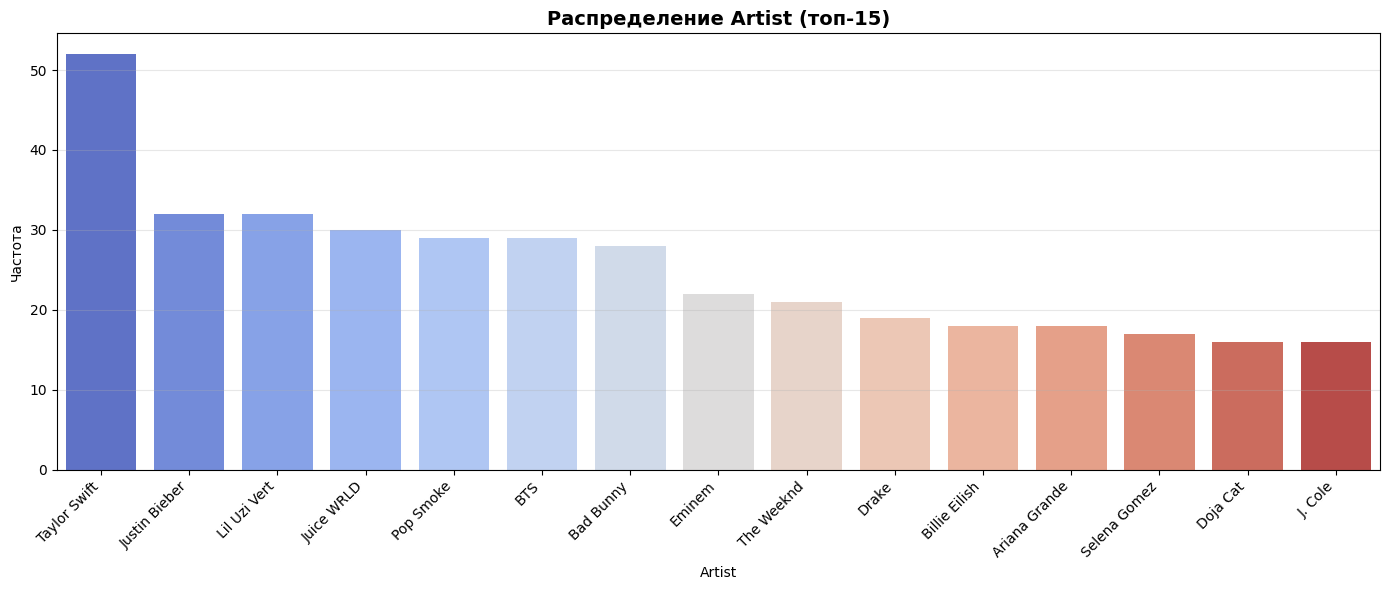

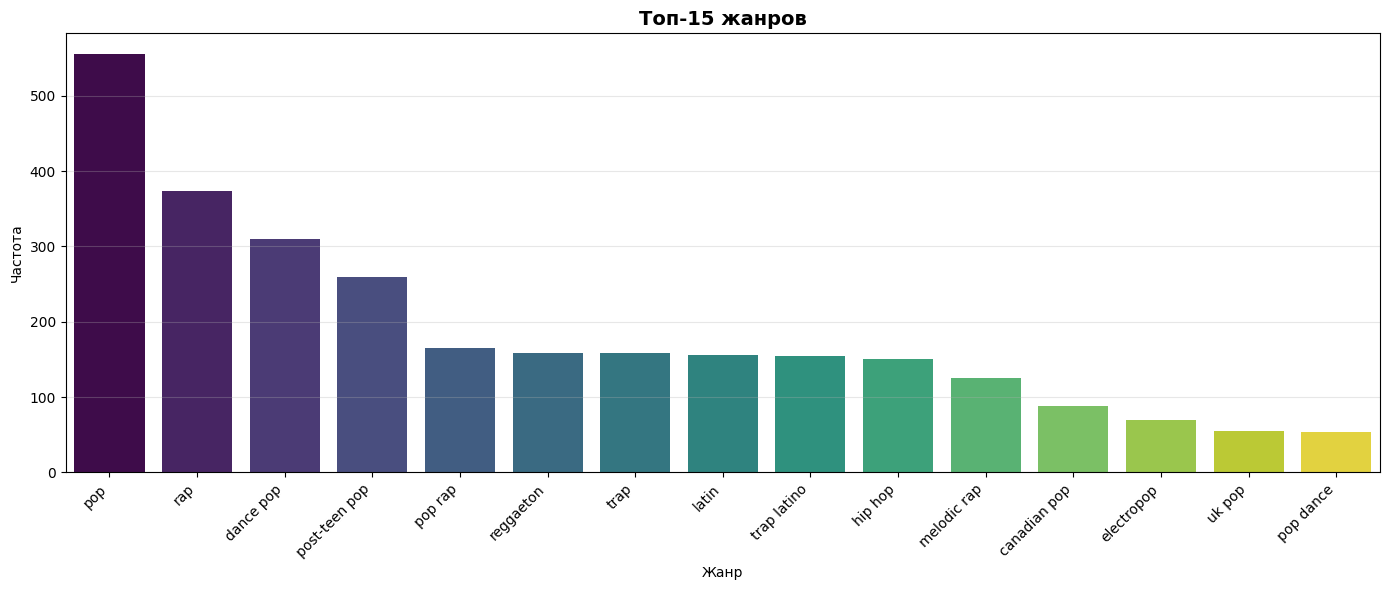

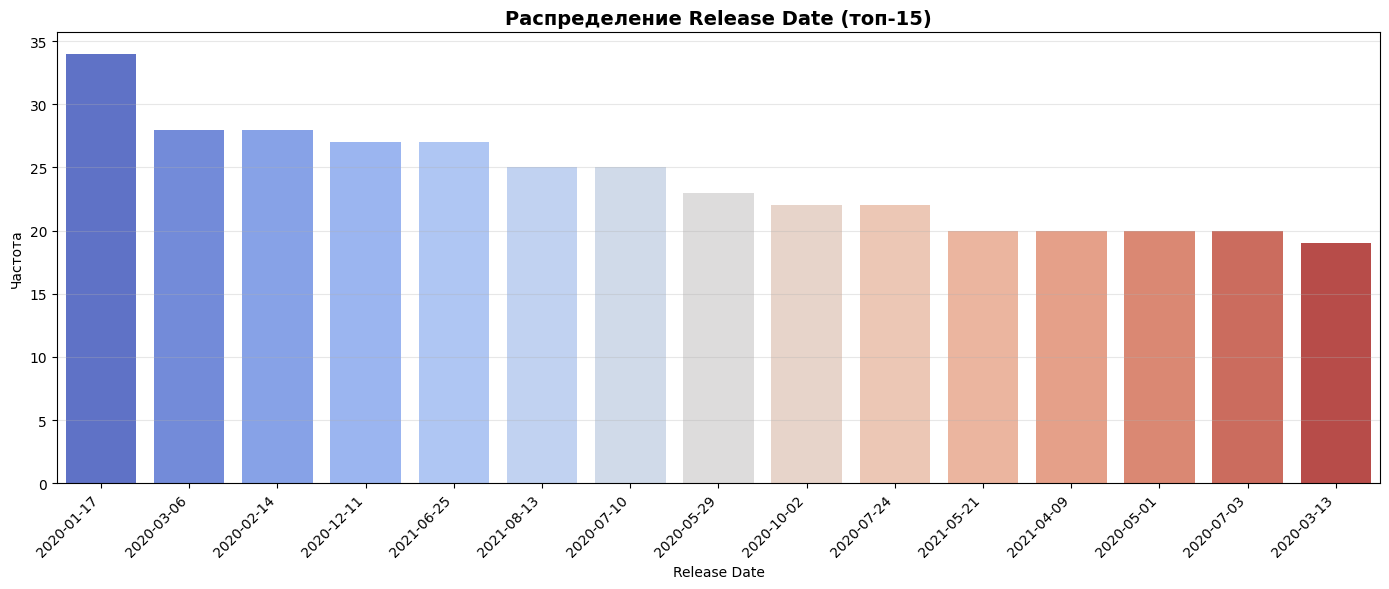

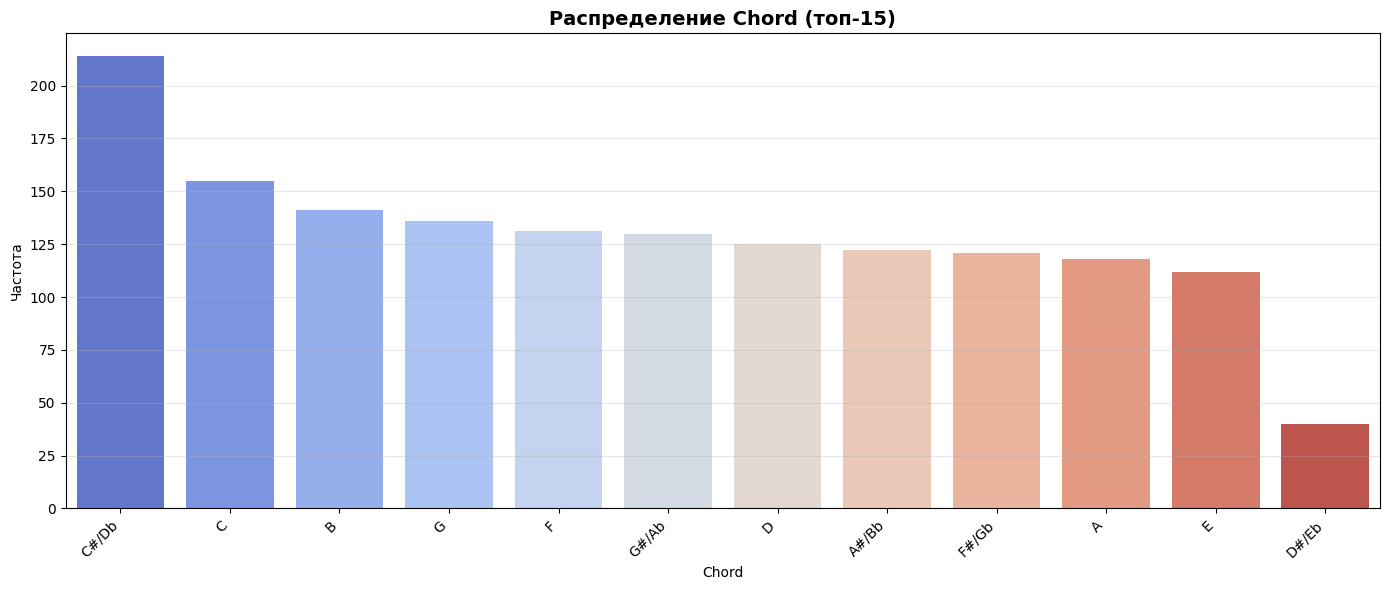

In [ ]:
# ВИЗУАЛИЗАЦИЯ КАТЕГОРИАЛЬНЫХ ПРИЗНАКОВ
categorical_cols1 = ['Artist', 'Genre', 'Release Date', 'Chord']

for col in categorical_cols1:
    plt.figure(figsize=(14, 6))

    if col == 'Genre':
        # Берем топ-15 жанров
        top_genres = dict(genre_counts.most_common(15))
        top_genres = dict(sorted(top_genres.items(), key=lambda x: x[1], reverse=True))

        sns.barplot(x=list(top_genres.keys()), y=list(top_genres.values()),
                   palette='viridis', hue=list(range(len(top_genres))), legend=False)
        plt.title(f'Топ-15 жанров', fontsize=14, fontweight='bold')
        plt.xlabel('Жанр')
        plt.ylabel('Частота')
        plt.xticks(rotation=45, ha='right')

    else:
        # Обычный countplot для остальных колонок
        freq = df_clean[col].value_counts().head(15)
        sns.barplot(x=freq.index, y=freq.values,
                   palette='coolwarm', hue=freq.index, legend=False)
        plt.title(f'Распределение {col} (топ-15)', fontsize=14, fontweight='bold')
        plt.xlabel(col)
        plt.ylabel('Частота')
        plt.xticks(rotation=45, ha='right')

    plt.grid(alpha=0.3, axis='y')
    plt.tight_layout()
    plt.show()

4.	Выявление аномалий (выбросов)
*	Визуальное обнаружение выбросов с помощью boxplot или violinplot.
*	При необходимости — статистическое обоснование (например, по межквартильному размаху).




АНАЛИЗ ВЫБРОСОВ (АНОМАЛИЙ)

────────────────────────────────────────────────────────────────────────────────
 Highest Charting Position
────────────────────────────────────────────────────────────────────────────────
  • Выбросов найдено: 0 (0.00% от 1545 строк)
  • Нижняя граница IQR: -113.0000
  • Верхняя граница IQR: 287.0000

────────────────────────────────────────────────────────────────────────────────
 Number of Times Charted
────────────────────────────────────────────────────────────────────────────────
  • Выбросов найдено: 170 (11.00% от 1545 строк)
  • Нижняя граница IQR: -15.5000
  • Верхняя граница IQR: 28.5000
  • Значения выбросов: [np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35), np.int64(36), np.int64(37), np.int64(38)]

────────────────────────────────────────────────────────────────────────────────
 Popularity
────────────────────────────────────────────────────────────────────────────────
  • Выбросов найдено: 60 

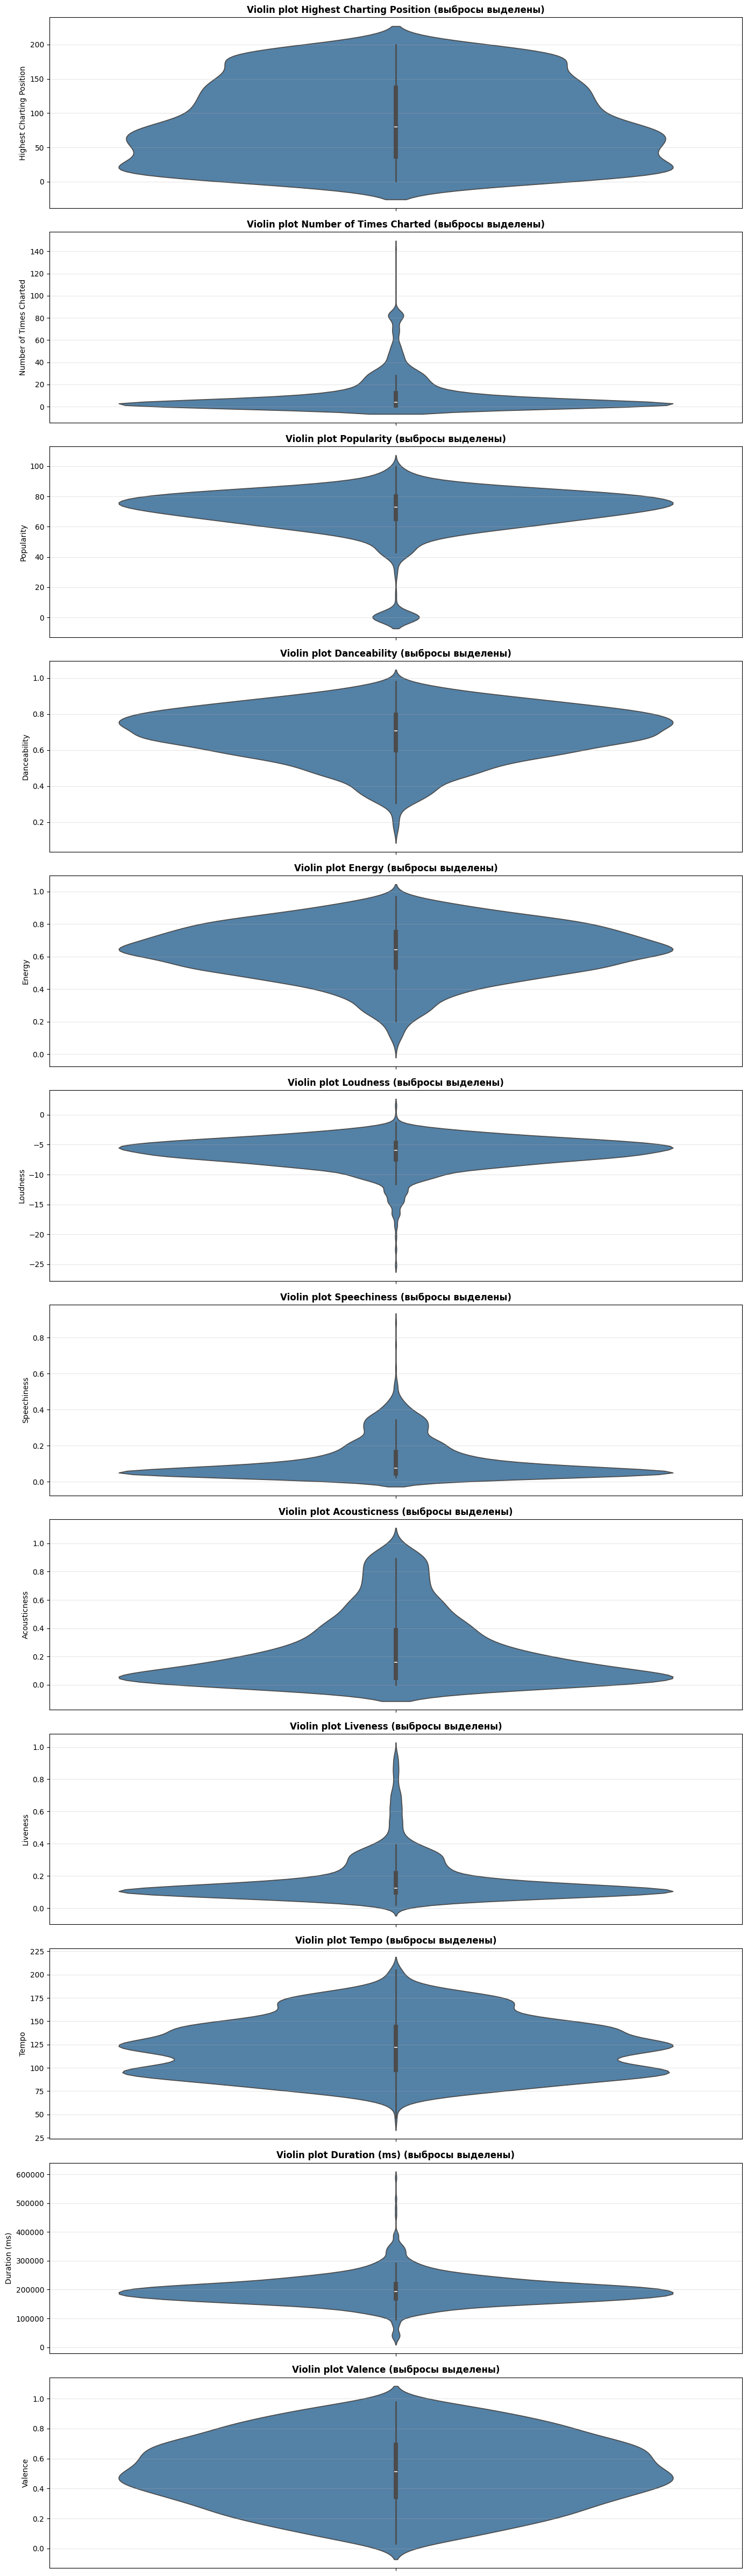

In [ ]:
# ВЫЯВЛЕНИЕ АНОМАЛИЙ (ВЫБРОСОВ)

print("\n\n" + "="*80)
print("АНАЛИЗ ВЫБРОСОВ (АНОМАЛИЙ)")
print("="*80)

# Используем числовые колонки без Index
numeric_cols_filtered = [col for col in numeric_cols if col != 'Index']

# Функция для расчета выбросов по методу межквартильного размаха (IQR)
def find_outliers_iqr(data, column):
    """Находит выбросы по методу IQR (межквартильный размах)"""
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[(data[column] < lower_bound) | (data[column] > upper_bound)]

    return outliers, lower_bound, upper_bound, len(outliers)

# Анализируем каждый числовой признак
outliers_summary = []

for col in numeric_cols_filtered:
    outliers, lower_bound, upper_bound, outlier_count = find_outliers_iqr(df_clean, col)

    total_rows = len(df_clean)
    outlier_percentage = (outlier_count / total_rows) * 100

    outliers_summary.append({
        'Признак': col,
        'Кол-во выбросов': outlier_count,
        '% от данных': f'{outlier_percentage:.2f}%',
        'Нижняя граница': f'{lower_bound:.4f}',
        'Верхняя граница': f'{upper_bound:.4f}'
    })

    print(f"\n{'─'*80}")
    print(f" {col}")
    print(f"{'─'*80}")
    print(f"  • Выбросов найдено: {outlier_count} ({outlier_percentage:.2f}% от {total_rows} строк)")
    print(f"  • Нижняя граница IQR: {lower_bound:.4f}")
    print(f"  • Верхняя граница IQR: {upper_bound:.4f}")

    if outlier_count > 0:
        print(f"  • Значения выбросов: {sorted(outliers[col].unique())[:10]}")  # Топ-10

# Выводим таблицу со сводкой
print(f"\n\n{'─'*80}")
print("СВОДКА ПО ВЫБРОСАМ")
print(f"{'─'*80}\n")
summary_df = pd.DataFrame(outliers_summary)
print(tabulate(summary_df, headers='keys', tablefmt='fancy_grid', showindex=False))

# ВИЗУАЛИЗАЦИЯ ВЫБРОСОВ

# Violin plot для всех числовых признаков
fig, axes = plt.subplots(len(numeric_cols_filtered), 1, figsize=(14, 4*len(numeric_cols_filtered)))

for idx, col in enumerate(numeric_cols_filtered):
    sns.violinplot(data=df_clean, y=col, ax=axes[idx], color='steelblue')
    axes[idx].set_title(f'Violin plot {col} (выбросы выделены)', fontsize=12, fontweight='bold')
    axes[idx].set_ylabel(col)
    axes[idx].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()


5.	Визуализация с помощью seaborn
Обязательно должны быть построены следующие графики:
*	countplot — для распределения категориального признака (с ≥20 категориями; при необходимости использовать поворот меток оси X).
*	histplot или kdeplot — для распределения числового признака.
*	scatterplot — с возможностью кодирования третьего признака цветом или размером (hue или size).
*	boxplot или violinplot — для оценки выбросов в числовых признаках.
*	clustermap — построенный на основе матрицы числовых признаков (например, после groupby по категориальному признаку с агрегацией, или на основе корреляций).



1️ COUNTPLOT - Распределение жанров (топ-25)


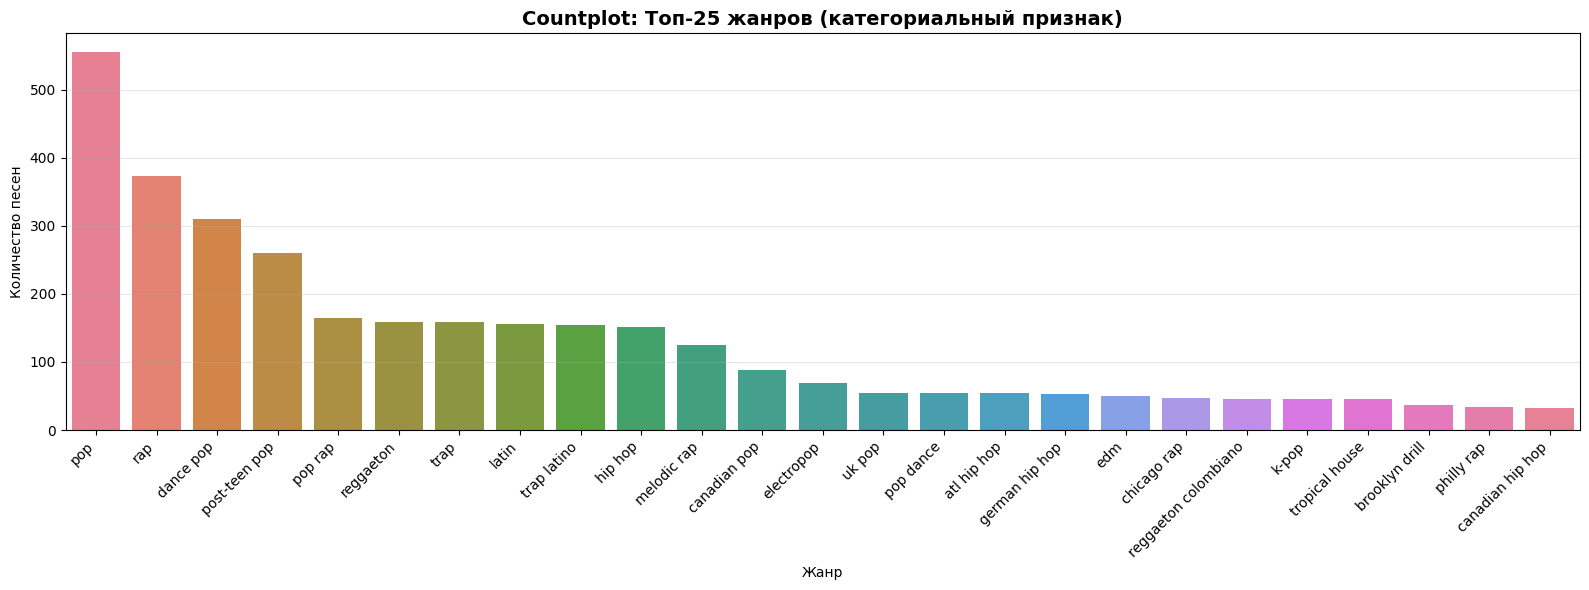

In [ ]:
# 1. COUNTPLOT - для жанров (категориальный признак с >20 категориями)
print("\n1️ COUNTPLOT - Распределение жанров (топ-25)")

plt.figure(figsize=(16, 6))
top_25_genres = dict(genre_counts.most_common(25))
top_25_genres = dict(sorted(top_25_genres.items(), key=lambda x: x[1], reverse=True))

sns.barplot(x=list(top_25_genres.keys()), y=list(top_25_genres.values()),
           palette='husl', hue=list(range(len(top_25_genres))), legend=False)
plt.title('Countplot: Топ-25 жанров (категориальный признак)', fontsize=14, fontweight='bold')
plt.xlabel('Жанр')
plt.ylabel('Количество песен')
plt.xticks(rotation=45, ha='right')
plt.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()



2️ HISTPLOT/KDEPLOT - Распределение Popularity


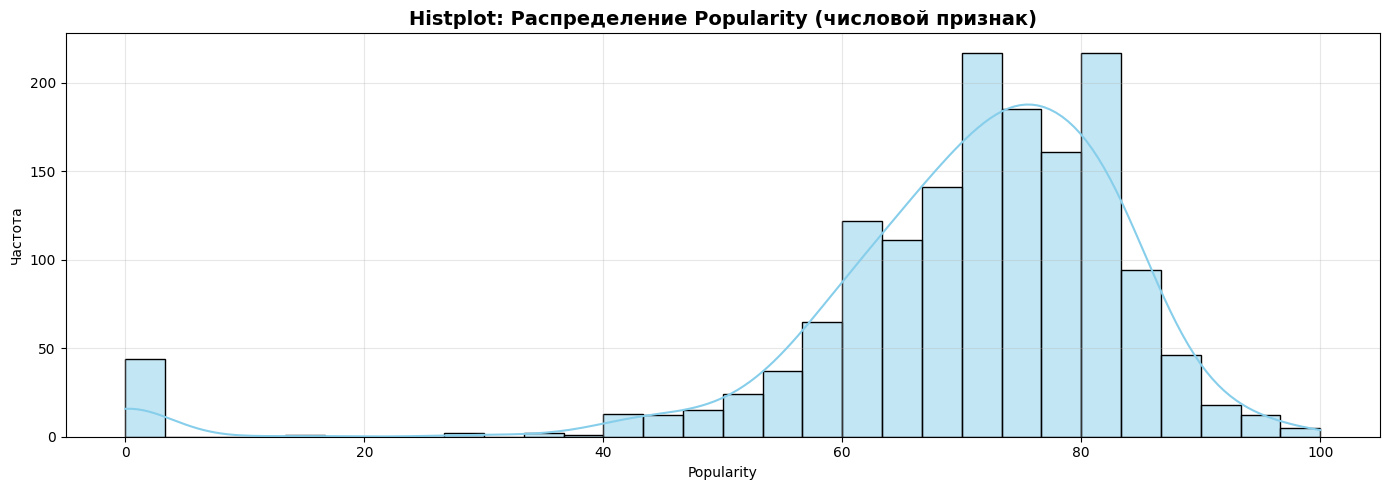

In [ ]:
# 2. HISTPLOT и KDEPLOT - для числовых признаков
print("\n2️ HISTPLOT/KDEPLOT - Распределение Popularity")

plt.figure(figsize=(14, 5))
sns.histplot(data=df_clean, x='Popularity', kde=True, bins=30, color='skyblue', edgecolor='black')
plt.title('Histplot: Распределение Popularity (числовой признак)', fontsize=14, fontweight='bold')
plt.xlabel('Popularity')
plt.ylabel('Частота')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


3️ SCATTERPLOT - Danceability vs Energy (окрашено по Popularity)


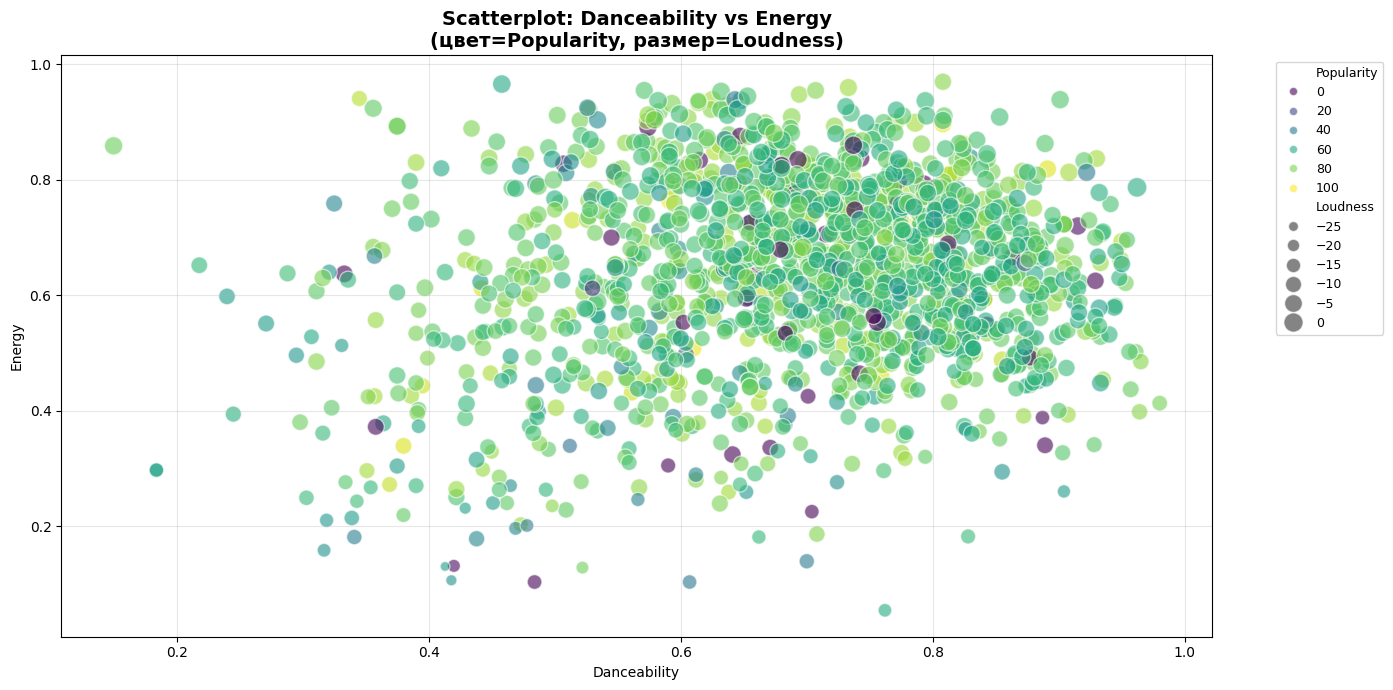

In [ ]:
# 3. SCATTERPLOT - с кодированием третьего признака
print("\n3️ SCATTERPLOT - Danceability vs Energy (окрашено по Popularity)")

plt.figure(figsize=(14, 7))
sns.scatterplot(data=df_clean, x='Danceability', y='Energy',
               hue='Popularity', size='Loudness', sizes=(50, 200),
               palette='viridis', alpha=0.6)
plt.title('Scatterplot: Danceability vs Energy\n(цвет=Popularity, размер=Loudness)',
         fontsize=14, fontweight='bold')
plt.xlabel('Danceability')
plt.ylabel('Energy')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


4️ BOXPLOT - Оценка выбросов в числовых признаках


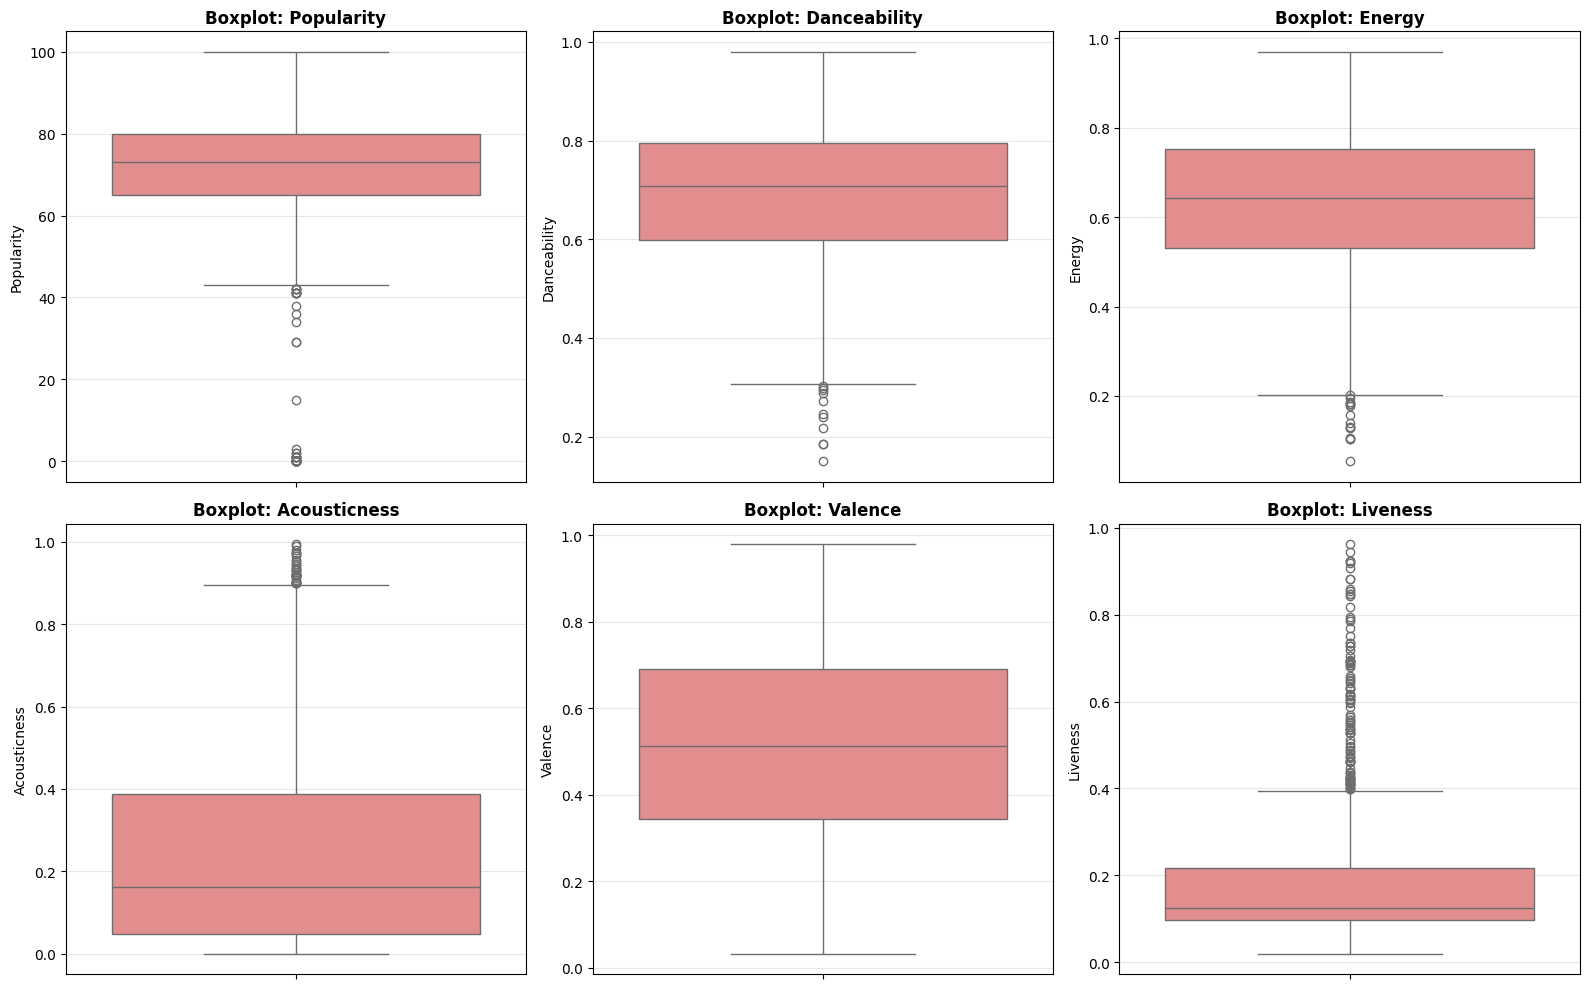

In [ ]:
# 4. BOXPLOT/VIOLINPLOT - для выбросов
print("\n4️ BOXPLOT - Оценка выбросов в числовых признаках")

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

features_for_box = ['Popularity', 'Danceability', 'Energy', 'Acousticness', 'Valence', 'Liveness']

for idx, col in enumerate(features_for_box):
    sns.boxplot(data=df_clean, y=col, ax=axes[idx], color='lightcoral')
    axes[idx].set_title(f'Boxplot: {col}', fontsize=12, fontweight='bold')
    axes[idx].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()


5️ CLUSTERMAP - Кластеризация по жанрам


<Figure size 1200x1400 with 0 Axes>

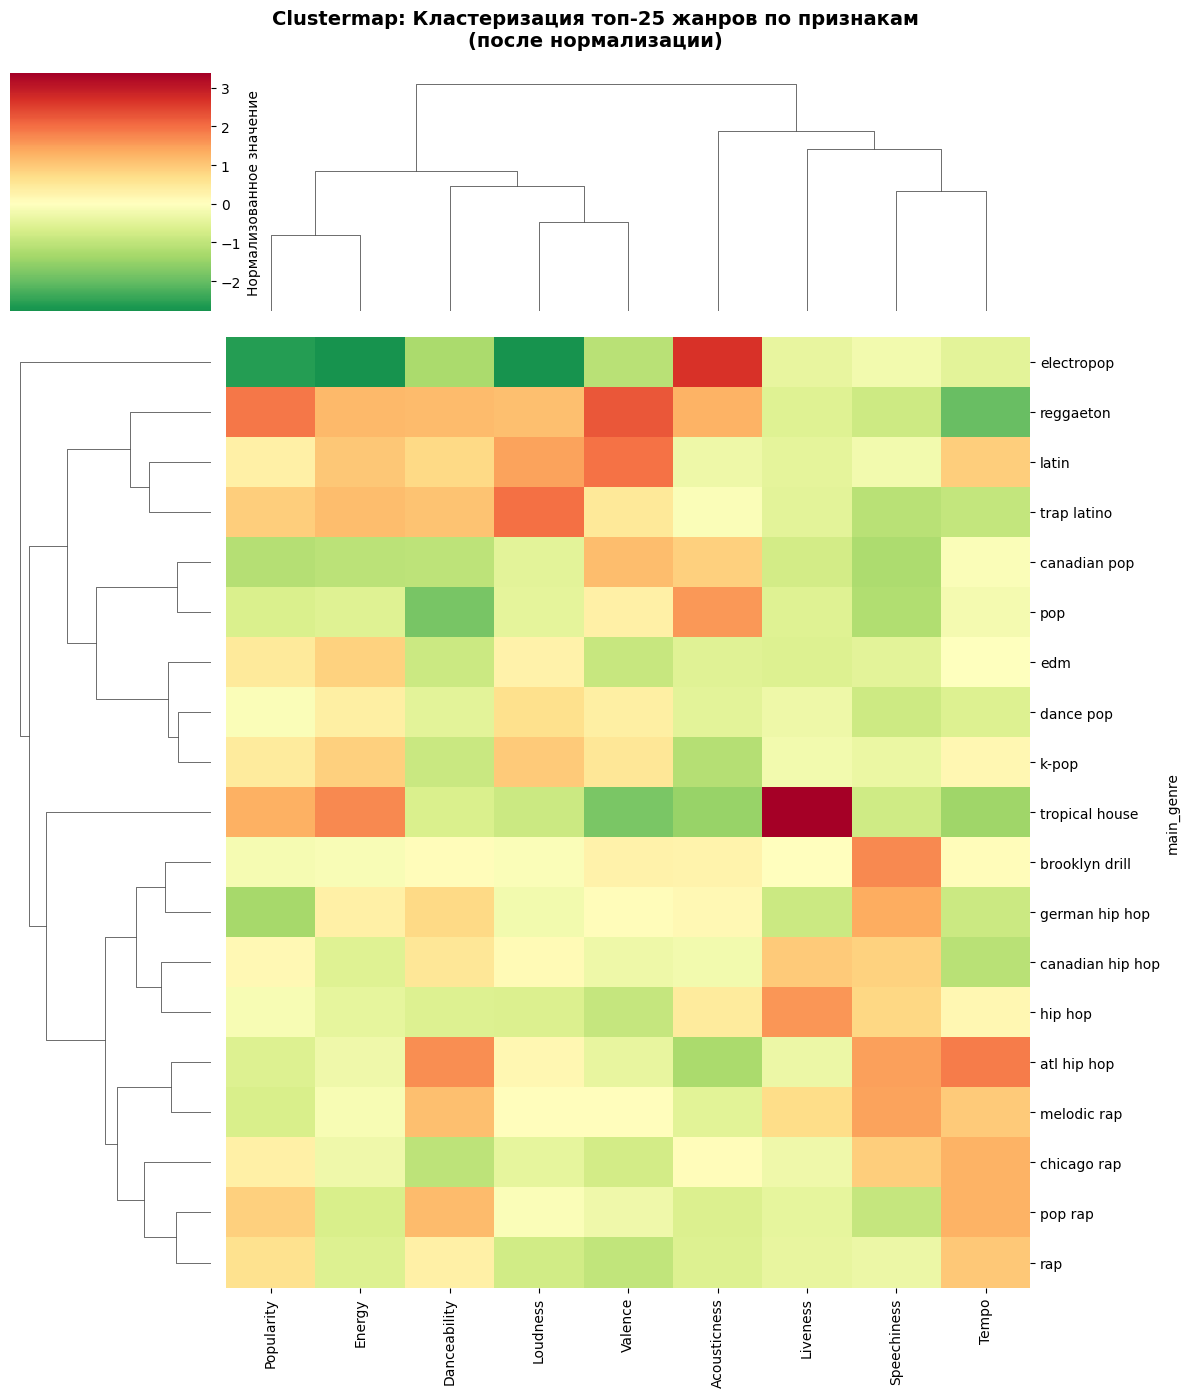

In [ ]:
# 5. CLUSTERMAP - иерархическая кластеризация
print("\n5️ CLUSTERMAP - Кластеризация по жанрам")

# Группируем по основному жанру и считаем среднее для числовых признаков
df_clean['main_genre'] = df_clean['Genre'].apply(lambda x: parse_genre(x)[0] if parse_genre(x) else 'Other')

# Берем топ-25 жанров
top_genres_for_cluster = list(genre_counts.most_common(25))
top_genres_list = [g[0] for g in top_genres_for_cluster]

df_for_cluster = df_clean[df_clean['main_genre'].isin(top_genres_list)]

# Группируем и считаем среднее
numeric_features = ['Popularity', 'Danceability', 'Energy', 'Loudness', 'Speechiness',
                   'Acousticness', 'Liveness', 'Tempo', 'Valence']
cluster_data = df_for_cluster.groupby('main_genre')[numeric_features].mean()

# Нормализуем данные для лучшей визуализации
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
cluster_data_scaled = pd.DataFrame(
    scaler.fit_transform(cluster_data),
    index=cluster_data.index,
    columns=cluster_data.columns
)

# Строим clustermap
plt.figure(figsize=(12, 14))
sns.clustermap(cluster_data_scaled, cmap='RdYlGn_r', center=0,
              figsize=(12, 14), cbar_kws={'label': 'Нормализованное значение'},
              method='ward')
plt.suptitle('Clustermap: Кластеризация топ-25 жанров по признакам\n(после нормализации)',
            fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()


## ИНТЕРПРЕТАЦИЯ И ВЫВОДЫ

### 1 Наиболее информативные признаки

На основе анализа данных наиболее информативными признаками являются:
- **Popularity** — показывает популярность трека на платформе, имеет широкое распределение (0-100)
- **Danceability, Energy, Valence** — музыкальные характеристики, хорошо дифференцируют треки по жанрам
- **Genre** — категориальный признак с 406 уникальными жанрами, позволяет сегментировать данные
- **Artist Followers** — косвенно указывает на известность исполнителя и влияние на популярность


### 2 Пропуски и аномалии

**Пропуски:**
- 75 строк с пустыми жанрами (заполнены модой по артистам или глобальной модой)
- 11 строк удалены из-за множественных пропусков в разных признаках

**Выбросы:**
- **Loudness**: выбросы в диапазоне -20 до 0 дБ (редкие очень тихие треки)
- **Duration**: выбросы в сторону очень длинных треков (>400 сек)
- **Tempo**: некоторые треки имеют экстремально высокий темп (>200 BPM)


### 3 Распределение жанров

**Топ жанры:**
- 'pop', 'rap', 'dance pop' — доминируют в датасете (>45% всех упоминаний)
- 'latin', 'reggaeton', 'trap latino' — хорошо представлены (~15%)
- Длинный хвост: 300+ жанров, каждый встречается <5 раз

**Вывод:** Датасет сильно смещен в сторону мейнстрим-жанров (pop, rap, dance), что отражает популярность этих жанров на Spotify.

### 4 Кластеры на clustermap

На иерархической кластеризации видны **3 основные группы жанров:**

1. **"Энергичные" жанры** (rap, hip-hop, drill): высокие Energy, Danceability, низкий Acousticness
2. **"Эмоциональные" жанры** (pop, ballads): высокие Valence, средние Energy, высокий Acousticness  
3. **"Экспериментальные" жанры** (electronic, ambient): низкие Danceability, высокие Acousticness/Liveness


### 5 Основные гипотезы

1. **Popularity зависит от жанра:** Pop и rap треки имеют выше среднюю популярность, экспериментальные жанры — ниже
2. **Danceability коррелирует с успехом:** Треки с высокой танцевальностью получают больше стримов
3. **Длина трека значима:** Оптимальная длина 3-4 минуты, очень длинные треки редко популярны
4. **Артисты с большим числом подписчиков имеют преимущество:** Коррелирует с количеством стримов

### Качество данных

 **Сильные стороны:**
- Полнота: 1545 строк, мало явных пропусков
- Разнообразие: 406 жанров, охватывает мейнстрим и нишевые направления
- Консистентность: признаки находятся в ожидаемых диапазонах

**Ограничения:**
- Смещение выборки в сторону популярных жанров
